# 💬📊 Data Analysis on Chatbot Conversations
                                                                                
####  📝 Objective: 
To analyze chatbot conversation data to gain insights into user behavior, identify common queries, analyze sentiment, and improve chatbot performance.

  

### 📦 Library Imports

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 📥 Loading the Dataset

In [18]:
chatbot=pd.read_csv('chatbot.csv')
chatbot

,tag,pattern,response
0,greeting,Hi,Hello!
1,greeting,Hi,Good to see you again!
2,greeting,Hi,"Hi there, how can I help?"
3,greeting,How are you?,Hello!
4,greeting,How are you?,Good to see you again!
...,...,...,...
523,ragging,ragging history,We are Proud to tell you that our college prov...
524,ragging,ragging incidents,We are Proud to tell you that our college prov...
525,hod,hod,"HODs differ for each branch, please be more sp..."
526,hod,hod name,"HODs differ for each branch, please be more sp..."


## 📊 General Data Exploration


 ### 📊 describe()

In [21]:
chatbot.describe()

,tag,pattern,response
count,528,528,528
unique,38,397,49
top,name,what are you,"Our university offers Information Technology, ..."
freq,52,8,27


### ✅ head ()

In [19]:
chatbot.head()

,tag,pattern,response
0,greeting,Hi,Hello!
1,greeting,Hi,Good to see you again!
2,greeting,Hi,"Hi there, how can I help?"
3,greeting,How are you?,Hello!
4,greeting,How are you?,Good to see you again!


### ▶️ tail()

In [20]:
chatbot.tail()

,tag,pattern,response
523,ragging,ragging history,We are Proud to tell you that our college prov...
524,ragging,ragging incidents,We are Proud to tell you that our college prov...
525,hod,hod,"HODs differ for each branch, please be more sp..."
526,hod,hod name,"HODs differ for each branch, please be more sp..."
527,hod,who is the hod,"HODs differ for each branch, please be more sp..."


In [34]:
chatbot.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 528 entries, 0 to 527
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   tag       528 non-null    object
 1   pattern   528 non-null    object
 2   response  528 non-null    object
dtypes: object(3)
memory usage: 12.5+ KB


In [35]:
chatbot.dtypes

tag         object
pattern     object
response    object
dtype: object

In [38]:
chatbot.sample(4)

,tag,pattern,response
8,greeting,Is anyone there?,"Hi there, how can I help?"
49,goodbye,Goodbye,Come back soon
175,number,phone number,You can contact at: NUMBER
519,ragging,is ragging done here,We are Proud to tell you that our college prov...


In [39]:
chatbot.index

RangeIndex(start=0, stop=528, step=1)

In [37]:
chatbot.shape

(528, 3)

In [40]:
chatbot.columns

Index(['tag', 'pattern', 'response'], dtype='object')

In [41]:
chatbot['pattern']

0                     Hi
1                     Hi
2                     Hi
3           How are you?
4           How are you?
             ...        
523      ragging history
524    ragging incidents
525                  hod
526             hod name
527       who is the hod
Name: pattern, Length: 528, dtype: object

In [42]:
chatbot['pattern'][100]

'your name'

In [43]:
chatbot[1:5]

,tag,pattern,response
1,greeting,Hi,Good to see you again!
2,greeting,Hi,"Hi there, how can I help?"
3,greeting,How are you?,Hello!
4,greeting,How are you?,Good to see you again!


In [44]:
chatbot[-3:-1]

,tag,pattern,response
525,hod,hod,"HODs differ for each branch, please be more sp..."
526,hod,hod name,"HODs differ for each branch, please be more sp..."


In [45]:
chatbot['pattern']=='How are you?'

0      False
1      False
2      False
3       True
4       True
       ...  
523    False
524    False
525    False
526    False
527    False
Name: pattern, Length: 528, dtype: bool

## 🧹 Data Cleaning and Preprocessing

In [46]:
print(chatbot.duplicated())

0      False
1      False
2      False
3      False
4      False
       ...  
523    False
524    False
525    False
526    False
527    False
Length: 528, dtype: bool


In [62]:
chatbot.reset_index()

,index,tag,pattern,response
0,0,greeting,HI,Hello!
1,1,greeting,HI,Good to see you again!
2,2,greeting,HI,"Hi there, how can I help?"
3,3,greeting,HOW ARE YOU?,Hello!
4,4,greeting,HOW ARE YOU?,Good to see you again!
...,...,...,...,...
523,523,ragging,RAGGING HISTORY,We are Proud to tell you that our college prov...
524,524,ragging,RAGGING INCIDENTS,We are Proud to tell you that our college prov...
525,525,hod,HOD,"HODs differ for each branch, please be more sp..."
526,526,hod,HOD NAME,"HODs differ for each branch, please be more sp..."


In [48]:
chatbot.isnull()

,tag,pattern,response
0,False,False,False
1,False,False,False
2,False,False,False
3,False,False,False
4,False,False,False
...,...,...,...
523,False,False,False
524,False,False,False
525,False,False,False
526,False,False,False


In [49]:
chatbot.isnull().sum()

tag         0
pattern     0
response    0
dtype: int64

In [50]:
pd.get_dummies(chatbot)

,tag_admission,tag_canteen,tag_college intake,tag_committee,tag_computerhod,tag_course,tag_creator,tag_document,tag_event,tag_extchod,...,"response_To know about placement visit <a target=""_blank"" href=""PLACEMENT INFORMATION LINK FROM YOUR UNIVERSITY WEBSITE IF THEY HAVE"">here</a>","response_To know more about document required visit <a target=""_blank"" href=""ADD LINK OF ADMISSION GUIDANCE DOCUMENT FROM YOUR UNIVERSITY WEBSITE""> here</a>","response_We are Proud to tell you that our college provides ragging free environment, and we have strict rules against ragging",response_XYZ is college principal and if you need any help then call your branch hod first.That is more appropriate,"response_You can ask me questions regarding college, and i will try to answer them",response_You can call me Mind Reader.,response_You can contact at: NUMBER,response_please use appropriate language,"response_we serve Franky, Locho, Alu-puri, Kachori, Khavsa, Thaali and many more on menu","response_welcome, anything else i can assist you with?"
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
523,False,False,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
524,False,False,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
525,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
526,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [63]:
chatbot.reset_index()

,index,tag,pattern,response
0,0,greeting,HI,Hello!
1,1,greeting,HI,Good to see you again!
2,2,greeting,HI,"Hi there, how can I help?"
3,3,greeting,HOW ARE YOU?,Hello!
4,4,greeting,HOW ARE YOU?,Good to see you again!
...,...,...,...,...
523,523,ragging,RAGGING HISTORY,We are Proud to tell you that our college prov...
524,524,ragging,RAGGING INCIDENTS,We are Proud to tell you that our college prov...
525,525,hod,HOD,"HODs differ for each branch, please be more sp..."
526,526,hod,HOD NAME,"HODs differ for each branch, please be more sp..."


## 📋 Data Grouping

In [51]:
chatbot['response'].value_counts()

response
Our university offers Information Technology, computer Engineering, Mechanical engineering,Chemical engineering, Civil engineering and extc Engineering.                                    27
Many government scholarships are supported by our university. For details and updates visit <a target="_blank" href="(SCHOLARSHIP DETAILS LINK)">here</a>                                   26
For Fee detail visit <a target="_blank" href="LINK"> here</a>                                                                                                                               23
For hostel detail visit <a target="_blank" href="ADD YOUR HOSTEL DETAIL PDF LINK OR ANY INFORMATION LINK OR ADD YOU OWN ANSWERS"> here</a>                                                  22
College is open 8am-5pm Monday-Saturday!                                                                                                                                                    17
College students                    

In [52]:
p=chatbot.groupby('tag').mean
p

<bound method GroupBy.mean of <pandas.core.groupby.generic.DataFrameGroupBy object at 0x0000029CB0FBC6B0>>

In [53]:
chatbot['pattern'].nunique

<bound method IndexOpsMixin.nunique of 0                     Hi
1                     Hi
2                     Hi
3           How are you?
4           How are you?
             ...        
523      ragging history
524    ragging incidents
525                  hod
526             hod name
527       who is the hod
Name: pattern, Length: 528, dtype: object>

In [54]:
chatbot['pattern'] = chatbot['pattern'].str.lower().str.strip()
chatbot['pattern']

0                     hi
1                     hi
2                     hi
3           how are you?
4           how are you?
             ...        
523      ragging history
524    ragging incidents
525                  hod
526             hod name
527       who is the hod
Name: pattern, Length: 528, dtype: object

In [58]:
pattern_count=chatbot['pattern'].value_counts()
pattern_count

pattern
WHAT ARE YOU              8
I GOT TO GO               4
HAVE A GOOD DAY           4
DO YOU HAVE A NAME        4
YOUR NAME                 4
                         ..
HOW TO GET IN HOSTEL      1
WHAT IS THE HOSTEL FEE    1
HOSTEL CAPACITY           1
HOSTEL                    1
WHO IS THE HOD            1
Name: count, Length: 395, dtype: int64

In [55]:
chatbot['pattern']=chatbot['pattern'].str.upper().str.strip()
chatbot['pattern']

0                     HI
1                     HI
2                     HI
3           HOW ARE YOU?
4           HOW ARE YOU?
             ...        
523      RAGGING HISTORY
524    RAGGING INCIDENTS
525                  HOD
526             HOD NAME
527       WHO IS THE HOD
Name: pattern, Length: 528, dtype: object

In [66]:
chatbot.reset_index()

,index,tag,pattern,response
0,0,greeting,HI,Hello!
1,1,greeting,HI,Good to see you again!
2,2,greeting,HI,"Hi there, how can I help?"
3,3,greeting,HOW ARE YOU?,Hello!
4,4,greeting,HOW ARE YOU?,Good to see you again!
...,...,...,...,...
523,523,ragging,RAGGING HISTORY,We are Proud to tell you that our college prov...
524,524,ragging,RAGGING INCIDENTS,We are Proud to tell you that our college prov...
525,525,hod,HOD,"HODs differ for each branch, please be more sp..."
526,526,hod,HOD NAME,"HODs differ for each branch, please be more sp..."


## 📈 Data Visualization

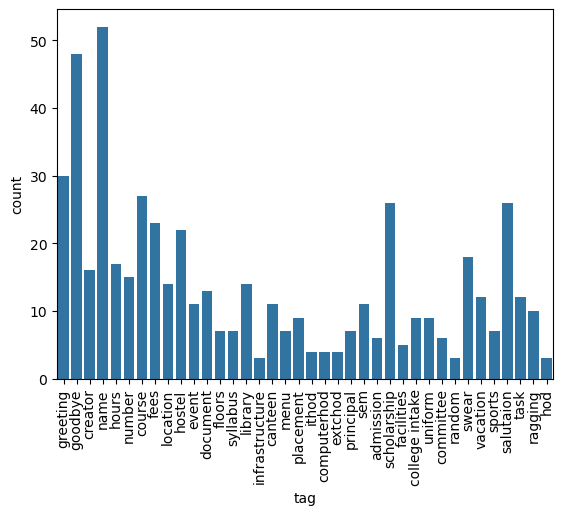

In [56]:
sns.countplot(data=chatbot, x='tag')
plt.xticks(rotation=90)
plt.show()


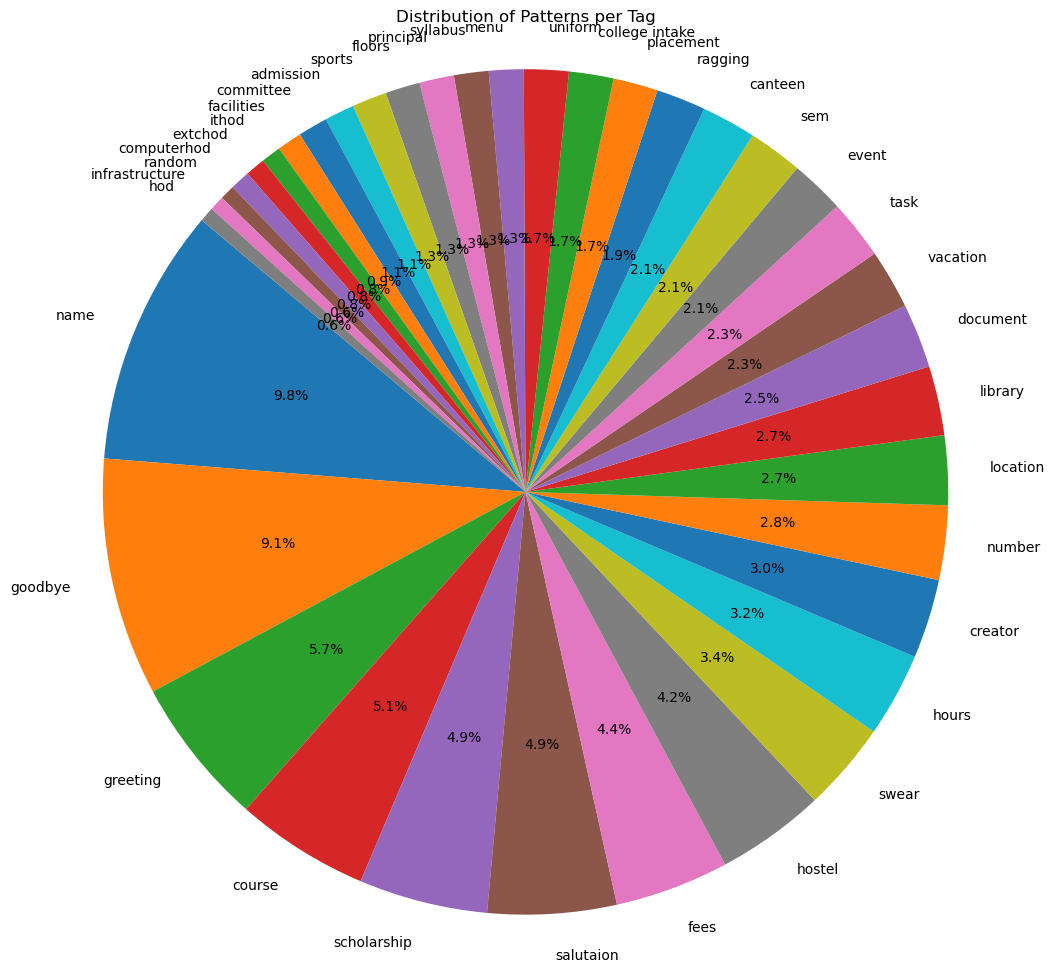

In [89]:
plt.figure(figsize=(12,12))
plt.pie(tag_counts, labels=tag_counts.index, autopct='%1.1f%%', startangle=140)
plt.title('Distribution of Patterns per Tag')
plt.axis('equal')  
plt.show()


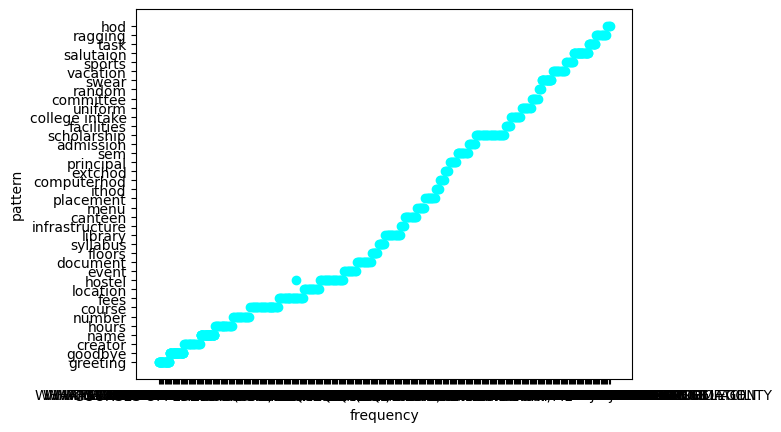

In [75]:
plt.scatter(chatbot['pattern'],chatbot['tag'],color='aqua')
plt.yticks(rotation=0)
plt.xlabel('frequency')
plt.ylabel('pattern')
plt.show()

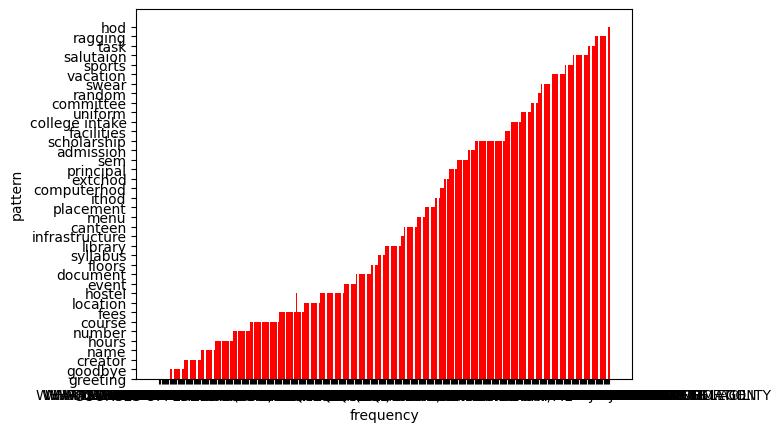

In [91]:
plt.bar(chatbot['pattern'],chatbot['tag'],color='red')
plt.yticks(rotation=0)
plt.xlabel('frequency')
plt.ylabel('pattern')
plt.show()

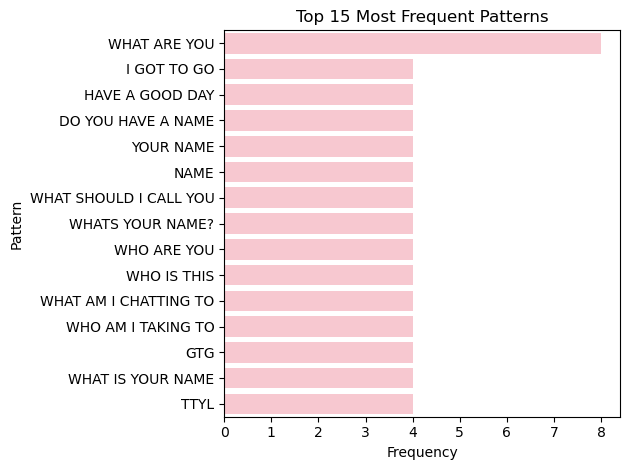

In [59]:
top_patterns = chatbot['pattern'].value_counts().head(15)
sns.barplot(x=top_patterns.values, y=top_patterns.index, color='pink')
plt.xlabel('Frequency')
plt.ylabel('Pattern')
plt.title('Top 15 Most Frequent Patterns')
plt.tight_layout()
plt.show()


Text(0, 0.5, 'Pattern')

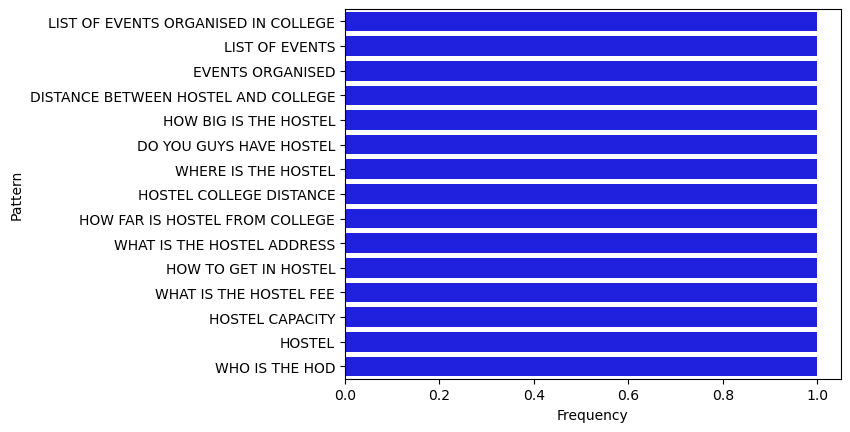

In [73]:
least_pattern=chatbot['pattern'].value_counts().tail(15)
sns.barplot(x=least_pattern.values,y=least_pattern.index,color='blue')
plt.xlabel('Frequency')
plt.ylabel('Pattern')

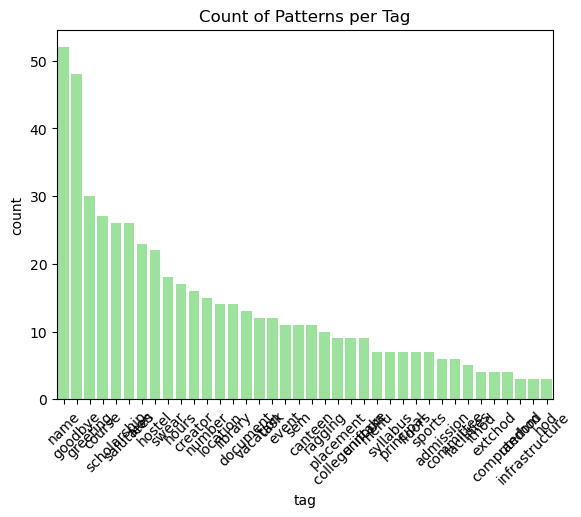

In [88]:
sns.countplot(data=chatbot, x='tag', order=chatbot['tag'].value_counts().index, color='lightgreen')
plt.xticks(rotation=45)
plt.title('Count of Patterns per Tag')
plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_21172\3016837143.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='tag', y='pattern_length', data=chatbot, palette='Reds')


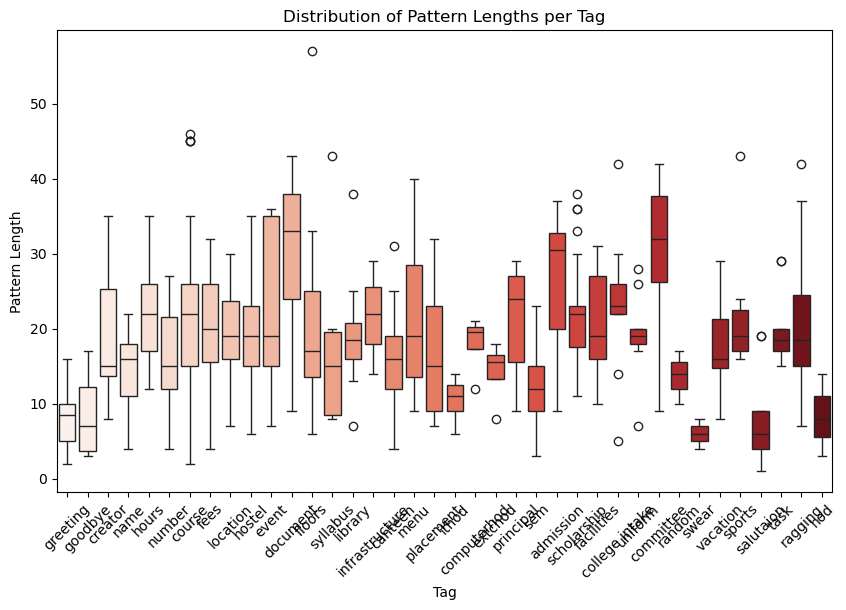

In [98]:
chatbot['pattern_length'] = chatbot['pattern'].apply(len)
plt.figure(figsize=(10, 6))
sns.boxplot(x='tag', y='pattern_length', data=chatbot, palette='Reds')
plt.xticks(rotation=45)
plt.xlabel('Tag')
plt.ylabel('Pattern Length')
plt.title('Distribution of Pattern Lengths per Tag')
plt.show()


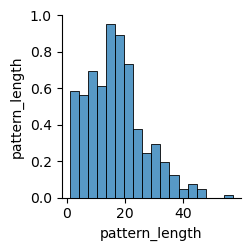

In [129]:
sns.pairplot(chatbot)
plt.

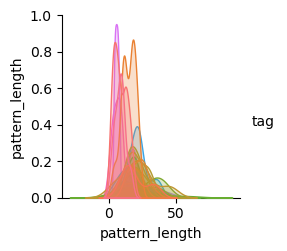

In [115]:
sns.pairplot(chatbot, hue='tag', markers=['o', 'D', 's','b','g'])  

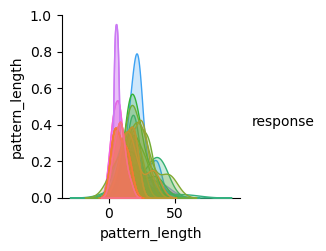

In [122]:
sns.pairplot(chatbot, hue='response', markers=['o', 'D', 's','b','g'])  